## HW2: Interpretable Machine Learning with Bankruptcy Prediction[¶](#HW2:-Interpretable-Machine-Learning-with-Bankruptcy-Prediction)


### Setup[¶](#Setup)


In [1]:
# if any of the following packages are missing, please install them before proceeding
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import shap

np.random.seed(42)


In [2]:
# load data and partition into train and test sets
# please run the following code exactly to ensure reproducibility
data = pd.read_csv("bankruptcy.csv")
Y = data["D"]
X = data.drop(columns=["D"])
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)
# this cell should return (105, 24) (105,) (27, 24) (27,)



(105, 24) (105,) (27, 24) (27,)



One label detail is important: in this dataset `D = 1` means *healthy*
and `D = 0` means *failed*. Since the assignment asks for class-1
performance, I highlight the healthy-firm row in each report. I still
include the full report, ROC-AUC, and confusion matrix so performance on
failed firms is visible. The `scoring="f1"` setting also uses class 1 as
the positive class, so it optimizes F1 for healthy firms. The full
dataset is balanced, but the 27-firm test set contains 18 failed and 9
healthy firms. Because that test set is small, even one or two
predictions can noticeably change the metrics, so I also use
cross-validation as a more stable check.

I also set up a small dictionary of readable names for the 24 ratios
(R1, R2, ...) so the charts aren't just cryptic codes.


In [3]:
# Human-readable names for the 24 accounting ratios (from the case description)
RATIO_NAMES = {
    "R1": "CASH/CURDEBT",  "R2": "CASH/SALES",    "R3": "CASH/ASSETS",   "R4": "CASH/DEBTS",
    "R5": "CFFO/SALES",    "R6": "CFFO/ASSETS",   "R7": "CFFO/DEBTS",    "R8": "COGS/INV",
    "R9": "CURASS/CURDEBT","R10": "CURASS/SALES", "R11": "CURASS/ASSETS","R12": "CURDEBT/DEBTS",
    "R13": "INC/SALES",    "R14": "INC/ASSETS",   "R15": "INC/DEBTS",    "R16": "UBCDEP/SALES",
    "R17": "INCDEP/ASSETS","R18": "INCDEP/DEBTS", "R19": "SALES/REC",    "R20": "SALES/ASSETS",
    "R21": "ASSETS/DEBTS", "R22": "WCFO/SALES",   "R23": "WCFO/ASSETS",  "R24": "WCFO/DEBTS",
}
def labeled(idx):
    return [f"{r} ({RATIO_NAMES[r]})" for r in idx]

# 5-fold stratified CV reused for tuning both tree models (small dataset -> use CV, not a single split)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def report(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(f"=== {name} ===")
    print(classification_report(Y_test, pred, digits=3))
    cm = confusion_matrix(Y_test, pred)
    print("Confusion matrix [rows = true 0/1, cols = pred 0/1]:\n", cm)
    print(f"ROC-AUC: {roc_auc_score(Y_test, proba):.3f}")
    print(f"Recall on FAILED firms (class 0): {cm[0,0]/cm[0].sum():.3f}  "
          f"-> the model misses {cm[0,1]} of {cm[0].sum()} real failures")


### Model 1: Decision Tree[¶](#Model-1:-Decision-Tree)


In [4]:
# Build a simple decision tree model, report its performance (for class 1), and report global interpretation
# Follow best practices for model training evaluation

# Small dataset, so a full-depth tree would just overfit. Tune the depth with CV on the
# training data, then check the test set once.
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 3, 4, 5, None], "min_samples_leaf": [1, 3, 5, 10]},
    scoring="f1", cv=cv,
)
dt_grid.fit(X_train, Y_train)
dt = dt_grid.best_estimator_
print("Best params:", dt_grid.best_params_)
print("CV f1 (train):", round(dt_grid.best_score_, 3))



Best params: {'max_depth': 4, 'min_samples_leaf': 3}
CV f1 (train): 0.781



In [5]:
# Performance on the held-out test set (class 1 = healthy firms; class 0 = failed firms both shown)
report(dt, "Decision Tree")



=== Decision Tree ===
              precision    recall  f1-score   support

           0      0.929     0.722     0.812        18
           1      0.615     0.889     0.727         9

    accuracy                          0.778        27
   macro avg      0.772     0.806     0.770        27
weighted avg      0.824     0.778     0.784        27

Confusion matrix [rows = true 0/1, cols = pred 0/1]:
 [[13  5]
 [ 1  8]]
ROC-AUC: 0.852
Recall on FAILED firms (class 0): 0.722  -> the model misses 5 of 18 real failures



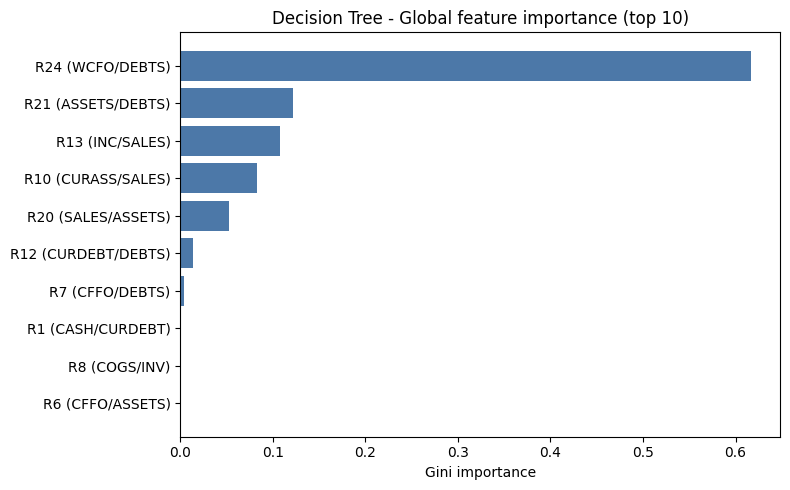


Non-zero importances (the tree only splits on these):
R24    0.6172
R21    0.1214
R13    0.1078
R10    0.0833
R20    0.0522
R12    0.0142
R7     0.0039
dtype: float64



In [6]:
# Global interpretation: impurity-based (Gini) feature importance
dt_imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
top_dt = dt_imp.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_dt.index), top_dt.values, color="#4C78A8")
plt.xlabel("Gini importance")
plt.title("Decision Tree - Global feature importance (top 10)")
plt.tight_layout()
plt.show()

print("Non-zero importances (the tree only splits on these):")
print(dt_imp[dt_imp > 0].round(4))


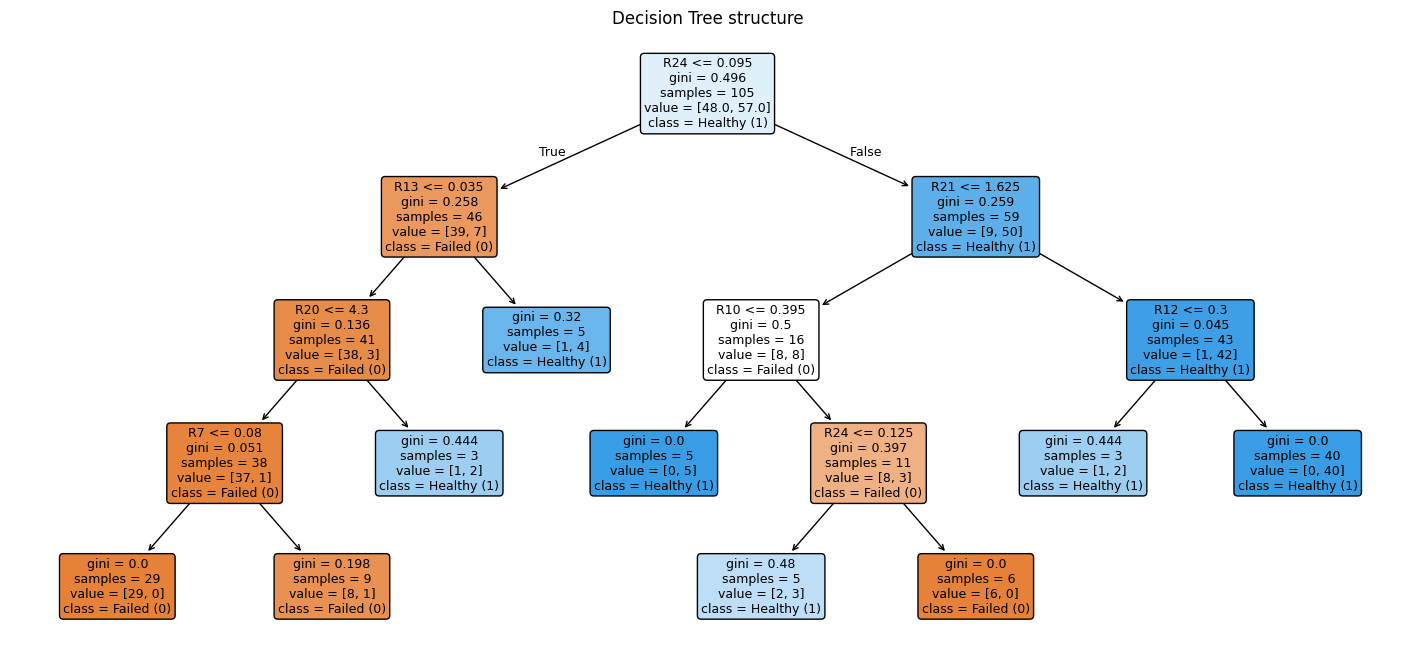


Root split: R24 (WCFO/DEBTS) <= 0.095
  next split: R13 (INC/SALES) <= 0.035
  next split: R21 (ASSETS/DEBTS) <= 1.625



In [7]:
# The tree is shallow enough to read directly - the most literal "global interpretation" there is
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=X.columns, class_names=["Failed (0)", "Healthy (1)"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree structure")
plt.show()

# Read the top of the tree in words
t = dt.tree_
root = X.columns[t.feature[0]]
print(f"Root split: {root} ({RATIO_NAMES[root]}) <= {t.threshold[0]:.3f}")
for child in (t.children_left[0], t.children_right[0]):
    if t.feature[child] >= 0:
        fc = X.columns[t.feature[child]]
        print(f"  next split: {fc} ({RATIO_NAMES[fc]}) <= {t.threshold[child]:.3f}")


**Reading the tree.** The root split is on `WCFO/DEBTS` (working capital
from operations relative to total debt), and the next splits include
`INC/SALES` and `ASSETS/DEBTS`. Thus, this fitted tree relies heavily on
cash-flow, earnings, and asset-coverage ratios. That broadly overlaps
with the debt-coverage theme emphasized by the ensemble interpretations,
although the tree's overall feature ranking differs substantially and is
concentrated on only a few ratios.


### Model 2: Random Forest[¶](#Model-2:-Random-Forest)


In [8]:
# Build a random forest model, report its performance (for class 1), and report global interpretation
# Follow best practices for model training evaluation

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={"n_estimators": [200, 400], "max_depth": [3, 5, None], "min_samples_leaf": [1, 2, 4]},
    scoring="f1", cv=cv,
)
rf_grid.fit(X_train, Y_train)
rf = rf_grid.best_estimator_
print("Best params:", rf_grid.best_params_)
print("CV f1 (train):", round(rf_grid.best_score_, 3))



Best params: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}
CV f1 (train): 0.855



In [9]:
# Performance on the held-out test set
report(rf, "Random Forest")



=== Random Forest ===
              precision    recall  f1-score   support

           0      0.933     0.778     0.848        18
           1      0.667     0.889     0.762         9

    accuracy                          0.815        27
   macro avg      0.800     0.833     0.805        27
weighted avg      0.844     0.815     0.820        27

Confusion matrix [rows = true 0/1, cols = pred 0/1]:
 [[14  4]
 [ 1  8]]
ROC-AUC: 0.883
Recall on FAILED firms (class 0): 0.778  -> the model misses 4 of 18 real failures



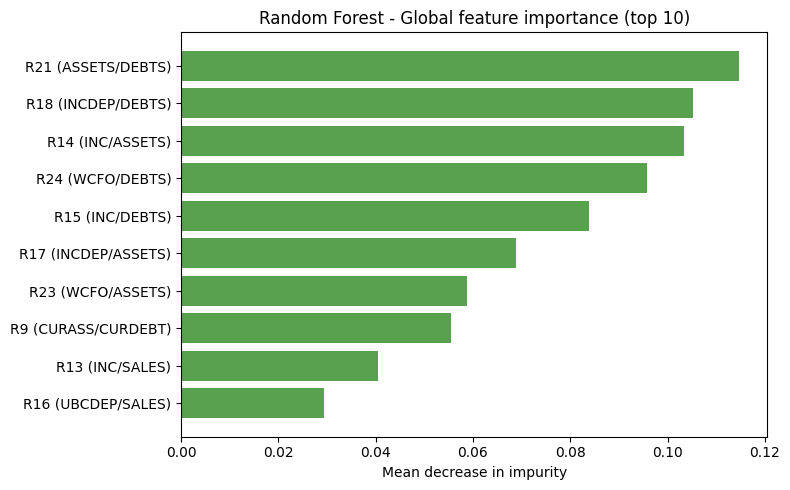


R21    0.1148
R18    0.1053
R14    0.1034
R24    0.0957
R15    0.0838
R17    0.0687
R23    0.0587
R9     0.0554
R13    0.0405
R16    0.0294
dtype: float64



In [10]:
# Global interpretation #1: impurity-based feature importance, averaged over all trees
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top_rf = rf_imp.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_rf.index), top_rf.values, color="#59A14F")
plt.xlabel("Mean decrease in impurity")
plt.title("Random Forest - Global feature importance (top 10)")
plt.tight_layout()
plt.show()

print(rf_imp.head(10).round(4))


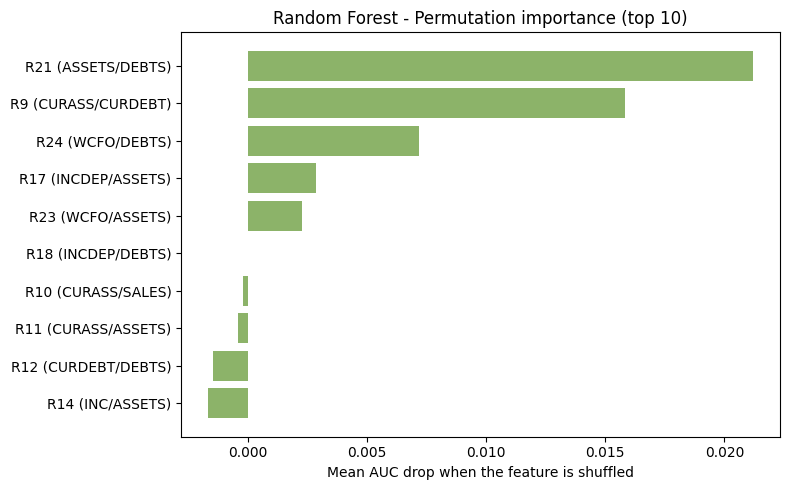


R21    0.0212
R9     0.0158
R24    0.0072
R17    0.0029
R23    0.0023
R18    0.0000
R10   -0.0002
R11   -0.0004
dtype: float64



In [11]:
# Global interpretation #2: permutation importance on the test set.
# Impurity importance can be biased toward features with more split points, so this is an
# unbiased cross-check (retrain-free: it shuffles each feature and measures the AUC drop).
perm = permutation_importance(rf, X_test, Y_test, scoring="roc_auc", n_repeats=30, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
top_p = perm_imp.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_p.index), top_p.values, color="#8CB369")
plt.xlabel("Mean AUC drop when the feature is shuffled")
plt.title("Random Forest - Permutation importance (top 10)")
plt.tight_layout()
plt.show()

print(perm_imp.head(8).round(4))


**Note on permutation importance.** Its *top* features — `ASSETS/DEBTS`,
`CURASS/CURDEBT`, `WCFO/DEBTS` — are consistent with the broader
debt-coverage theme. But notice how quickly it flattens to near-zero.
Correlated predictors can dilute permutation importance because
shuffling one ratio may leave correlated substitutes available to the
forest; the 27-row test set also makes these estimates unstable. I
therefore use permutation importance and SHAP as complementary
model-interpretation views rather than treating either as uniquely
authoritative, especially because correlated features can affect both
methods' feature-level attributions.


### Model 3: SHAP[¶](#Model-3:-SHAP)



SHAP values shape (class 1): (27, 24)



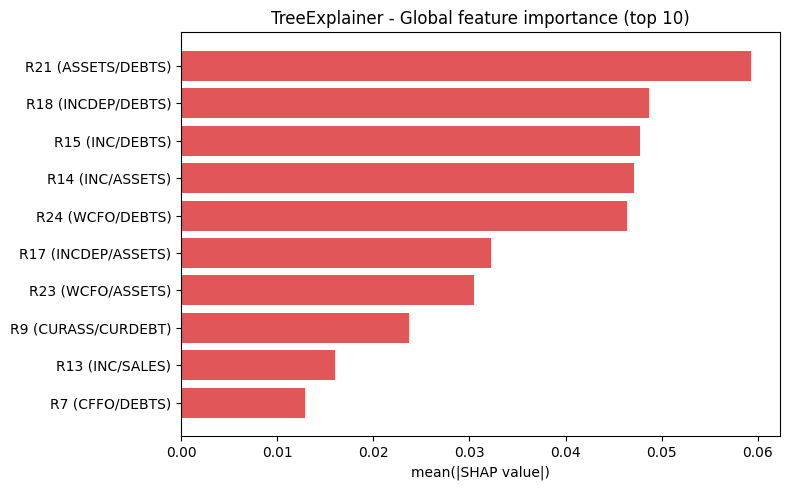


R21    0.0593
R18    0.0487
R15    0.0478
R14    0.0471
R24    0.0464
R17    0.0322
R23    0.0305
R9     0.0237
R13    0.0160
R7     0.0129
dtype: float64



In [12]:
# Use SHAP to explain your random forest model's predictions on the test set. Report global interpretation
# (i.e., you will need to aggregate SHAP values across all test samples in some way)
# Use TreeExplainer (it is designed to explain tree ensemble models):
# https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html

tree_explainer = shap.TreeExplainer(rf)
tree_sv = tree_explainer.shap_values(X_test)

# For a binary RF, TreeExplainer returns shape (n_samples, n_features, n_classes); take the class-1 slice.
tree_sv = np.array(tree_sv)
tree_sv1 = tree_sv[:, :, 1] if tree_sv.ndim == 3 else tree_sv
print("SHAP values shape (class 1):", tree_sv1.shape)

# Global view: average the absolute SHAP values over all test firms
tree_global = pd.Series(np.abs(tree_sv1).mean(axis=0), index=X.columns).sort_values(ascending=False)
top_t = tree_global.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_t.index), top_t.values, color="#E15759")
plt.xlabel("mean(|SHAP value|)")
plt.title("TreeExplainer - Global feature importance (top 10)")
plt.tight_layout()
plt.show()

print(tree_global.head(10).round(4))


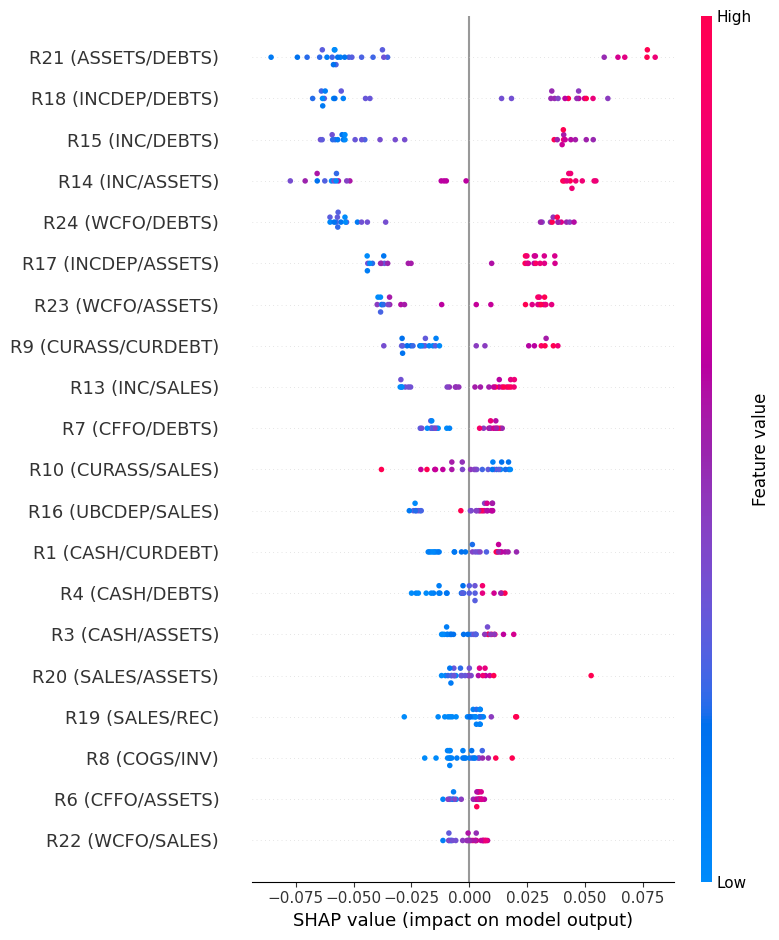

In [13]:
# SHAP beeswarm summary plot (direction + magnitude of each feature's effect on the class-1 prediction)
shap.summary_plot(tree_sv1, X_test, feature_names=[f"{c} ({RATIO_NAMES[c]})" for c in X.columns], show=True)



Kernel SHAP values shape: (27, 24)



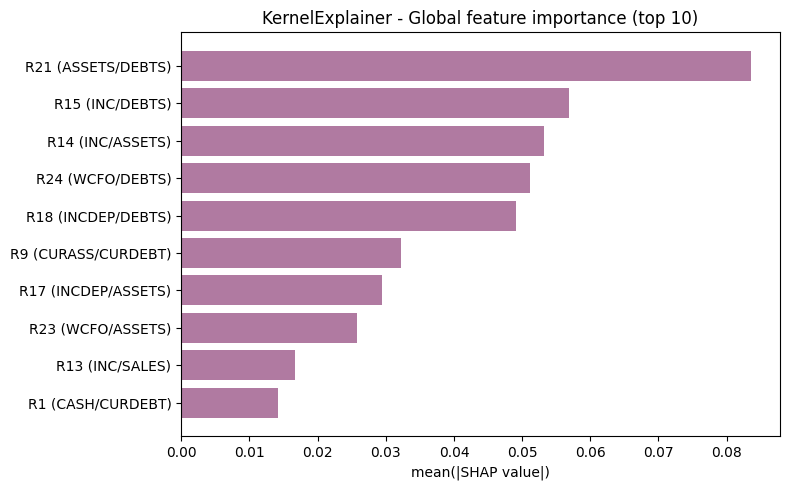


R21    0.0836
R15    0.0569
R14    0.0532
R24    0.0512
R18    0.0491
R9     0.0323
R17    0.0294
R23    0.0258
R13    0.0167
R1     0.0142
dtype: float64



In [14]:
# Now use a different SHAP explainer, such as KernelExplainer:
# https://shap.readthedocs.io/en/latest/generated/shap.KernelExplainer.html
# Report global interpretation

# KernelExplainer is model-agnostic. We explain the probability of class 1 (healthy).
# Use a compact k-means summary of the training data as the background distribution.
background = shap.kmeans(X_train, 10)

def rf_class1_proba(arr):
    # wrap as DataFrame so column names match (keeps sklearn quiet and consistent)
    return rf.predict_proba(pd.DataFrame(arr, columns=X.columns))[:, 1]

kernel_explainer = shap.KernelExplainer(rf_class1_proba, background)
kernel_sv = np.array(kernel_explainer.shap_values(X_test, nsamples=500, l1_reg="num_features(24)"))
print("Kernel SHAP values shape:", kernel_sv.shape)

# Global interpretation: mean absolute SHAP value across all test samples
kernel_global = pd.Series(np.abs(kernel_sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
top_k = kernel_global.head(10)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_k.index), top_k.values, color="#B07AA1")
plt.xlabel("mean(|SHAP value|)")
plt.title("KernelExplainer - Global feature importance (top 10)")
plt.tight_layout()
plt.show()

print(kernel_global.head(10).round(4))


### Comparing the rankings[¶](#Comparing-the-rankings)

To compare the methods properly instead of eyeballing separate charts, I
do two things: (1) line up every ranking in one table, and (2) measure
how much the rankings actually agree with a Spearman rank correlation.


In [15]:
# Line up the four global importance rankings. For the decision tree, features it never splits on
# have exactly zero importance, so I blank their rank instead of pretending they're "tied at 8th".
def ranked(series, mask_zero=False):
    r = series.rank(ascending=False, method="min")
    if mask_zero:
        r = r.where(series > 0, np.nan)
    return r

ranks = pd.DataFrame({
    "DT_rank":         ranked(dt_imp, mask_zero=True),
    "RF_rank":         ranked(rf_imp),
    "TreeSHAP_rank":   ranked(tree_global),
    "KernelSHAP_rank": ranked(kernel_global),
})
ranks["ratio"] = [RATIO_NAMES[r] for r in ranks.index]
order = ranks[["RF_rank", "TreeSHAP_rank", "KernelSHAP_rank"]].mean(axis=1).sort_values().index
print("Global-importance RANK by method (1 = most important; DT blank = zero importance):\n")
print(ranks.loc[order, ["ratio", "DT_rank", "RF_rank", "TreeSHAP_rank", "KernelSHAP_rank"]].head(12).to_string())



Global-importance RANK by method (1 = most important; DT blank = zero importance):

              ratio  DT_rank  RF_rank  TreeSHAP_rank  KernelSHAP_rank
R21    ASSETS/DEBTS      2.0      1.0            1.0              1.0
R18    INCDEP/DEBTS      NaN      2.0            2.0              5.0
R15       INC/DEBTS      NaN      5.0            3.0              2.0
R14      INC/ASSETS      NaN      3.0            4.0              3.0
R24      WCFO/DEBTS      1.0      4.0            5.0              4.0
R17   INCDEP/ASSETS      NaN      6.0            6.0              7.0
R9   CURASS/CURDEBT      NaN      8.0            8.0              6.0
R23     WCFO/ASSETS      NaN      7.0            7.0              8.0
R13       INC/SALES      3.0      9.0            9.0              9.0
R1     CASH/CURDEBT      NaN     11.0           13.0             10.0
R7       CFFO/DEBTS      7.0     14.0           10.0             11.0
R16    UBCDEP/SALES      NaN     10.0           12.0             14.0



In [16]:
# Quantify the agreement: Spearman rank correlation between the four rankings (all 24 features)
M = pd.DataFrame({"DT": dt_imp, "RF": rf_imp, "TreeSHAP": tree_global, "KernelSHAP": kernel_global})
spearman = M.corr(method="spearman")
print("Spearman rank-correlation between the global rankings:\n")
print(spearman.round(2))



Spearman rank-correlation between the global rankings:

              DT    RF  TreeSHAP  KernelSHAP
DT          1.00  0.17      0.23        0.20
RF          0.17  1.00      0.97        0.96
TreeSHAP    0.23  0.97      1.00        0.98
KernelSHAP  0.20  0.96      0.98        1.00



## Written answers[¶](#Written-answers)

### Question 1[¶](#Question-1)

Model building, evaluation, and interpretation are all in the code
above. The short version, on the held-out test set (class 1 = healthy):

| Model                                | Precision (cls 1) | Recall (cls 1) | F1 (cls 1) | Accuracy | ROC-AUC | Recall on failures (cls 0) |
|--------------------------------------|-------------------|----------------|------------|----------|---------|----------------------------|
| Decision tree (depth 4, min\_leaf 3) | 0.615             | 0.889          | 0.727      | 0.778    | 0.852   | 0.722                      |
| Random forest (200 trees, depth 3)   | 0.667             | 0.889          | 0.762      | 0.815    | 0.883   | 0.778                      |

**Class 1 is the healthy-firm class.** For the decision tree, precision
of 0.615 means that 61.5% of firms predicted healthy are actually
healthy; recall of 0.889 means it identifies 88.9% of the healthy firms;
and the resulting class-1 F1 score is 0.727. For the random forest,
precision increases to 0.667 while recall remains 0.889, producing a
higher class-1 F1 score of 0.762. Thus, on this held-out test set, the
random forest is the stronger model for the assignment's requested
class-1 evaluation.

The random forest also has higher overall accuracy and ROC-AUC and
misses fewer actual failures. However, the test set has only 27 firms,
including 9 healthy firms, so a few predictions can change recall and F1
quite a bit. The cross-validation result (RF class-1 F1 ≈ 0.855) is
therefore a useful second check. Here `scoring="f1"` optimizes class 1,
which means healthy firms in this dataset. For a real bankruptcy
application I would also focus closely on class 0: the random forest
still misses about 22% of failing firms, so I would tune the decision
threshold and keep expert review in the process. For interpretation, I
compare impurity importance with permutation importance and also read
the small tree's splits directly.

### Question 2 — do the different methods agree?[¶](#Question-2-%E2%80%94-do-the-different-methods-agree?)

For the random forest, the methods agree very strongly. Random-forest
importance, TreeSHAP, and KernelSHAP have Spearman correlations of about
**0.96–0.98**. All three rank `ASSETS/DEBTS` (R21) first and then
emphasize a similar group of debt-coverage, earnings, cash-flow, and
liquidity ratios. Permutation importance also highlights R21, R9, and
R24. The beeswarm adds direction: in this fitted model, higher coverage
ratios generally push predictions toward class 1, or healthy.

The single decision tree is the outlier. Its ranking has only a weak
correlation with the random-forest-based rankings (about **0.17–0.23**).
It gives roughly 62% of its importance to `WCFO/DEBTS` and ranks several
sales-based ratios much higher. This makes sense because a single tree
chooses one feature at each split; when ratios are correlated, the
selected feature can receive most of the credit while similar features
receive little or none. The small sample can make that ranking more
sensitive as well.

TreeSHAP and KernelSHAP use the same top-eight features but order a few
of them differently. KernelSHAP is an approximation, and the explainer
setup can also affect small differences.

**Overall conclusion:** The global interpretations are highly consistent
across random-forest importance, TreeSHAP, and KernelSHAP, which
identify the same broad solvency, debt-coverage, profitability,
cash-flow, and liquidity signals. The decision tree is the main
exception because it concentrates credit on a small number of selected
split variables. I therefore place greater confidence in patterns that
remain stable across the three agreeing methods than in the exact
ranking from any single method.

### Question 3 — presenting this to executives[¶](#Question-3-%E2%80%94-presenting-this-to-executives)

**Executive takeaway derived from Question 2:** Across the three
interpretation methods that agree most strongly, the model mainly
assesses whether a company has enough assets, income, and cash flow to
cover its debt. That cross-method agreement makes this broad message
more dependable than any exact feature rank. The single decision tree
gives more weight to a few sales-based ratios, so I would present those
as a secondary, less stable signal rather than ignore the disagreement.

For the slide, I would use the consensus chart below, which averages
ranks across random-forest importance, TreeSHAP, and KernelSHAP. I would
show the top ratios as a related group rather than claim that the
difference between ranks two and three is important. I would also
mention the decision-tree disagreement so the audience sees that the
ranking is not identical across every model.

I would translate the ratio names into plain English: how leveraged the
firm is and whether its earnings and cash flow can cover its
obligations. I would also show the error rate. Since the random forest
misses about 22% of actual failures on this small test set, it should be
used to flag firms for review, not make the final decision by itself.
Finally, these are predictive importance results, not proof that any
ratio causes bankruptcy or that changing it will prevent failure.


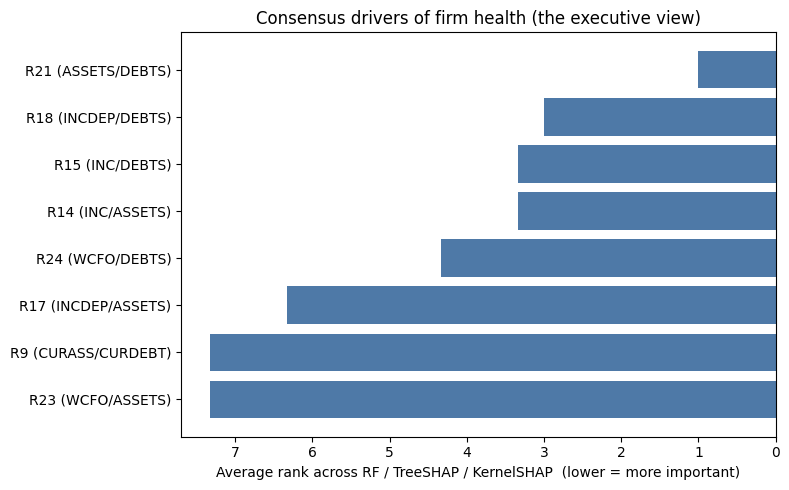


Consensus top model signals:
     avg_rank         meaning
R21      1.00    ASSETS/DEBTS
R18      3.00    INCDEP/DEBTS
R15      3.33       INC/DEBTS
R14      3.33      INC/ASSETS
R24      4.33      WCFO/DEBTS
R17      6.33   INCDEP/ASSETS
R9       7.33  CURASS/CURDEBT
R23      7.33     WCFO/ASSETS



In [17]:
# The one importance chart I would actually show executives: a CONSENSUS ranking that averages
# the rank across the three methods that agree (RF, TreeSHAP, KernelSHAP), so no single method drives it.
consensus = (M[["RF", "TreeSHAP", "KernelSHAP"]]
             .rank(ascending=False)
             .mean(axis=1)
             .sort_values())
top_c = consensus.head(8)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(labeled(top_c.index), top_c.values, color="#4E79A7")
plt.xlabel("Average rank across RF / TreeSHAP / KernelSHAP  (lower = more important)")
plt.title("Consensus model signals of firm health (the executive view)")
plt.gca().invert_xaxis()  # most important on top-right
plt.tight_layout()
plt.show()
print("Consensus top model signals:")
print(pd.DataFrame({"avg_rank": consensus.head(8).round(2),
                    "meaning": [RATIO_NAMES[r] for r in consensus.head(8).index]}).to_string())


### Question 4 — recommendations to clients[¶](#Question-4-%E2%80%94-recommendations-to-clients)

The global importance results describe the average pattern, but
individual at-risk firms may reach the same prediction for different
reasons. Instead of giving every client the same advice, I use local
SHAP values to explore whether the flagged firms fall into useful
groups.

The workflow is: score the portfolio, keep firms with a predicted
probability of health below 0.5, summarize how each firm's features
contribute to that prediction, and cluster those local SHAP profiles.
This creates possible distress profiles based on model output rather
than using the true failure label, which would not be available for a
live client.


In [18]:
# 1) Local SHAP profiles for the class-1 (healthy) model output, for every firm
sv_all = np.array(shap.TreeExplainer(rf).shap_values(X))
sv_all = sv_all[:, :, 1] if sv_all.ndim == 3 else sv_all
sv_all = pd.DataFrame(sv_all, index=X.index, columns=X.columns)

# 2) Keep the firms the MODEL flags as at-risk (deployable: uses predictions, not the D label)
p_healthy = rf.predict_proba(X)[:, 1]
at_risk = X.index[p_healthy < 0.5]
print(f"Model flags {len(at_risk)} of {len(X)} firms as at-risk; "
      f"{int((Y.loc[at_risk] == 0).sum())} of those actually failed "
      f"({(Y.loc[at_risk] == 0).mean():.0%} precision on the flag).")

risk_sv = sv_all.loc[at_risk]
Z = StandardScaler().fit_transform(risk_sv.values)

# 3) Choose k with the silhouette score (report it honestly rather than hand-picking)
for k in [2, 3, 4]:
    lab_k = KMeans(k, n_init=10, random_state=42).fit_predict(Z)
    print(f"k={k}: silhouette = {silhouette_score(Z, lab_k):.3f}")



Model flags 62 of 132 firms as at-risk; 57 of those actually failed (92% precision on the flag).




k=2: silhouette = 0.246




k=3: silhouette = 0.164
k=4: silhouette = 0.148



In [19]:
# The silhouette favors k = 2, and that split is also the most interpretable, so I use it.
k = 2
km = KMeans(k, n_init=10, random_state=42).fit(Z)
seg = pd.Series(km.labels_, index=at_risk, name="segment")
print("Segment sizes:", seg.value_counts().sort_index().to_dict())

healthy_med = X[Y == 1].median()
rows = []
for c in range(k):
    members = risk_sv[seg == c]
    members_x = X.loc[members.index]
    drivers = members.mean().sort_values().head(5)   # most negative class-1 SHAP = strongest contribution toward the model's failure prediction
    for r in drivers.index:
        rows.append({"segment": c, "n": len(members), "ratio": r, "meaning": RATIO_NAMES[r],
                     "mean_class1_SHAP": round(drivers[r], 3),
                     "seg_median_level": round(members_x[r].median(), 2),
                     "healthy_median": round(healthy_med[r], 2)})
seg_summary = pd.DataFrame(rows)
print(seg_summary.to_string(index=False))



Segment sizes: {0: 45, 1: 17}
 segment  n ratio        meaning  mean_class1_SHAP  seg_median_level  healthy_median
       0 45   R18   INCDEP/DEBTS            -0.061             -0.01            0.27
       0 45   R24     WCFO/DEBTS            -0.055             -0.02            0.22
       0 45   R14     INC/ASSETS            -0.053             -0.04            0.06
       0 45   R15      INC/DEBTS            -0.050             -0.06            0.13
       0 45   R21   ASSETS/DEBTS            -0.045              1.35            2.10
       1 17   R21   ASSETS/DEBTS            -0.069              1.40            2.10
       1 17    R9 CURASS/CURDEBT            -0.027              1.50            2.19
       1 17   R24     WCFO/DEBTS            -0.027              0.09            0.22
       1 17   R15      INC/DEBTS            -0.023              0.02            0.13
       1 17   R14     INC/ASSETS            -0.023              0.01            0.06



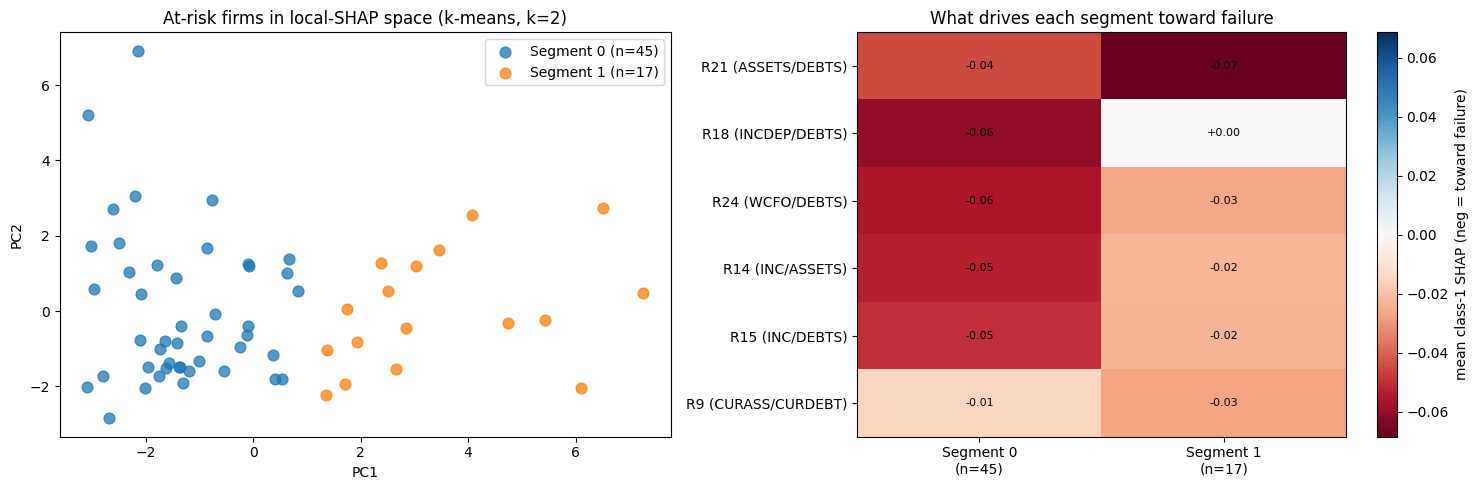

In [20]:
# Visualize the two archetypes two ways: a PCA scatter (are they actually separated?)
# and a heatmap of what drives each one.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

P = PCA(n_components=2, random_state=42).fit_transform(Z)
for c in range(k):
    m = (seg.values == c)
    axes[0].scatter(P[m, 0], P[m, 1], s=60, alpha=0.75, label=f"Segment {c} (n={m.sum()})")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("At-risk firms in local-SHAP space (k-means, k=2)")
axes[0].legend()

top_feats = seg_summary.groupby("ratio")["mean_class1_SHAP"].min().sort_values().head(8).index.tolist()
mat = pd.DataFrame({c: risk_sv[seg == c][top_feats].mean() for c in range(k)})
mat.index = [f"{r} ({RATIO_NAMES[r]})" for r in mat.index]
im = axes[1].imshow(mat.values, cmap="RdBu", vmin=-abs(mat.values).max(), vmax=abs(mat.values).max(), aspect="auto")
axes[1].set_xticks(range(k)); axes[1].set_xticklabels([f"Segment {c}\n(n={(seg==c).sum()})" for c in range(k)])
axes[1].set_yticks(range(len(mat.index))); axes[1].set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        axes[1].text(j, i, f"{mat.values[i,j]:+.2f}", ha="center", va="center", fontsize=8)
axes[1].set_title("What drives each segment toward failure")
plt.colorbar(im, ax=axes[1], label="mean class-1 SHAP (neg = toward failure)")
plt.tight_layout(); plt.show()


#### What the segments look like[¶](#What-the-segments-look-like)

The best silhouette score is at k = 2, but the score is only 0.246, so
the groups are not strongly separated. I treat them as two useful
patterns in this sample, not as fixed client types.

**Profitability / cash-flow distressed (about 45 firms).** The strongest
risk signals are earnings and cash-flow ratios such as `INCDEP/DEBTS`,
`WCFO/DEBTS`, `INC/ASSETS`, and `INC/DEBTS`. Their median values are
near or below zero; for example, median INC/ASSETS is about −0.04 versus
+0.06 for healthy firms. This suggests starting with the income
statement and cash-flow performance.

**Leverage & liquidity distressed (about 17 firms).** This group has
slightly positive median income ratios, but lower `ASSETS/DEBTS` (about
1.4 versus 2.1 for healthy firms) and `CURASS/CURDEBT` (about 1.5 versus
2.2). Its profile points more toward leverage and short-term liquidity.

I keep k = 2 because k = 3 has a lower silhouette score. The extra group
mainly splits the profitability pattern by severity, and the data do not
support treating that as a stable third segment.

#### Recommendations by segment[¶](#Recommendations-by-segment)

For the **profitability / cash-flow** group, I would first investigate
margins, pricing, cost of goods, supplier terms, loss-making products or
customers, and fixed costs. The near-term objective would be to
stabilize operating cash generation, with follow-up monitoring of
cash-flow-to-debt and income-to-assets relative to the firm's own
history and relevant peers.

For the **leverage & liquidity** group, I would first review debt
maturities, expensive debt, working capital, receivables, inventory, and
available liquidity. Refinancing, paying down debt, raising equity, or
selling non-core assets could be evaluated depending on the firm's
situation. Follow-up monitoring would emphasize assets-to-debt, current
assets-to-current debt, covenant headroom, and upcoming refinancing
needs.

For both groups, a simple early-warning dashboard could track
assets-to-debt and cash-flow-to-debt ratios against relevant peers.
These recommendations are hypotheses and areas to investigate, not
proven causal interventions. The model shows which financial measures
are associated with its predictions; it does not show that changing a
ratio will reduce bankruptcy risk. The segments also have weak
separation and were built from this 132-firm sample, so they should be
validated on new data and used with firm-specific analysis and expert
review.
